# MLP — DBO na entrada a partir de DQO e SST

A DBO de laboratório na entrada da planta é o alvo (`DBO-E`). O modelo recebe duas medições do mesmo ponto: a DQO (`DQO-E`) e os sólidos em suspensão (`SS-E`, o SST deste arquivo). A data não é variável e não organiza a divisão das amostras: cada dia entra como uma observação independente.

Dias em que falta `DBO-E`, `DQO-E` ou `SS-E` saem da tabela. Não há interpolação.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

plt.rcParams.update({
    "figure.figsize": (6.2, 4.6),
    "axes.grid": True,
    "grid.color": "0.85",
    "grid.linewidth": 0.6,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "medium",
})

COR = "#1f4e79"
COR_REF = "#c45c26"
ENTRADAS = ["DQO-E", "SS-E"]
ALVO = "DBO-E"
SEMENTE = 42


def raiz_repositorio() -> Path:
    aqui = Path.cwd().resolve()
    for candidato in [aqui, *aqui.parents]:
        if (candidato / "data" / "water-treatment-plant" / "water-treatment.data").exists():
            return candidato
    raise FileNotFoundError("Repositório SoftSensor não encontrado.")


RAIZ = raiz_repositorio()
sys.path.insert(0, str(RAIZ / "modelo"))
from dados import carregar

FIGURAS = RAIZ / "docs" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)


## Amostra

As três colunas vêm da entrada da planta. `SS-E` é o SST do arquivo; sólidos voláteis (`SSV-E`) ficam de fora.


In [2]:
bruto = carregar()
tabela = bruto.dropna(subset=[ALVO, *ENTRADAS]).loc[:, [ALVO, *ENTRADAS]].reset_index(drop=True)

print(f"dias no arquivo: {len(bruto)}")
print(f"dias com DBO, DQO e SST na entrada: {len(tabela)}")
print(f"dias removidos por valor ausente: {len(bruto) - len(tabela)}")
tabela.describe().round(2)


dias no arquivo: 527
dias com DBO, DQO e SST na entrada: 498
dias removidos por valor ausente: 29


,DBO-E,DQO-E,SS-E
count,498.00,498.00,498.00
mean,188.72,405.36,228.74
std,62.28,119.99,139.12
min,31.00,81.00,98.00
25%,146.25,324.25,170.00
50%,182.50,397.50,198.00
75%,223.00,472.75,243.50
max,438.00,941.00,2008.00


In [3]:
correlacao = tabela.corr(numeric_only=True).round(3)
correlacao


,DBO-E,DQO-E,SS-E
DBO-E,1.000,0.565,0.137
DQO-E,0.565,1.000,0.284
SS-E,0.137,0.284,1.000


## Divisão e validação cruzada

Oitenta por cento das linhas treinam o modelo e vinte por cento ficam reservadas para o teste. O sorteio é aleatório (`random_state=42`), sem usar a data.

A escolha da rede acontece só no treino, com validação cruzada de 5 partições embaralhadas. O critério é o MAE. O `StandardScaler` entra no `Pipeline`, então cada partição recalcula média e desvio apenas com as linhas daquela partição de treino. O conjunto de teste entra uma vez, depois da escolha.


In [4]:
X = tabela[ENTRADAS]
y = tabela[ALVO]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=SEMENTE, shuffle=True
)

cv = KFold(n_splits=5, shuffle=True, random_state=SEMENTE)
print(f"treino: {len(X_treino)}")
print(f"teste: {len(X_teste)}")
print(f"DBO média no treino: {y_treino.mean():.2f}")
print(f"DBO média no teste: {y_teste.mean():.2f}")


treino: 398
teste: 100
DBO média no treino: 188.14
DBO média no teste: 191.03


## MLP

A grade varia o tamanho da rede, a ativação e a regularização L2 (`alpha`). O otimizador é `lbfgs`, estável neste tamanho de amostra: cerca de 400 linhas de treino e duas entradas. A rede escolhida é reajustada no treino inteiro.


In [5]:
mlp = Pipeline([
    ("scaler", StandardScaler()),
    ("rede", MLPRegressor(
        solver="lbfgs",
        max_iter=1000,
        random_state=SEMENTE,
    )),
])

grade = {
    "rede__hidden_layer_sizes": [(8,), (16,), (32,), (16, 8), (32, 16)],
    "rede__activation": ["relu", "tanh"],
    "rede__alpha": [1e-4, 1e-3, 1e-2, 1e-1],
}

busca = GridSearchCV(
    mlp,
    grade,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    refit=True,
)
busca.fit(X_treino, y_treino)

rede = busca.best_estimator_.named_steps["rede"]
indice = busca.best_index_
cv_mae = -busca.cv_results_["mean_test_score"][indice]
cv_std = busca.cv_results_["std_test_score"][indice]

print("arquitetura:", busca.best_params_)
print(f"MAE na validação cruzada: {cv_mae:.2f} ± {cv_std:.2f}")
print(f"iterações até parar: {rede.n_iter_}")
print(f"convergência registrada: {rede.n_iter_ < rede.max_iter}")


arquitetura: {'rede__activation': 'relu', 'rede__alpha': 0.0001, 'rede__hidden_layer_sizes': (8,)}
MAE na validação cruzada: 39.19 ± 2.78
iterações até parar: 42
convergência registrada: True


In [6]:
ranking = pd.DataFrame(busca.cv_results_)
ranking["MAE"] = -ranking["mean_test_score"]
ranking["desvio"] = ranking["std_test_score"]
colunas_grade = [
    "param_rede__hidden_layer_sizes",
    "param_rede__activation",
    "param_rede__alpha",
    "MAE",
    "desvio",
]
ranking = ranking.sort_values("MAE").loc[:, colunas_grade].reset_index(drop=True)
visao = ranking.head(8).copy()
visao["param_rede__alpha"] = visao["param_rede__alpha"].map(lambda valor: f"{float(valor):.0e}")
visao["MAE"] = visao["MAE"].map(lambda valor: f"{valor:.2f}")
visao["desvio"] = visao["desvio"].map(lambda valor: f"{valor:.2f}")
visao


,param_rede__hidden_layer_sizes,param_rede__activation,param_rede__alpha,MAE,desvio
0,"(8,)",relu,1e-04,39.19,2.78
1,"(8,)",relu,1e-03,39.19,2.79
2,"(8,)",relu,1e-01,39.20,2.80
3,"(8,)",tanh,1e-01,39.63,2.70
4,"(8,)",tanh,1e-04,39.73,2.59
5,"(8,)",tanh,1e-02,39.77,2.73
6,"(8,)",relu,1e-02,39.79,3.35
7,"(16, 8)",relu,1e-02,39.99,3.55


## Teste

O teste compara o MLP com duas referências ajustadas no mesmo treino: a média da DBO e uma regressão linear de `DQO-E` e `SS-E`. A linear também passa pela mesma validação cruzada, sem grade de hiperparâmetros.


In [7]:
def avaliar(y_obs, y_prev):
    return {
        "MAE": mean_absolute_error(y_obs, y_prev),
        "RMSE": float(np.sqrt(mean_squared_error(y_obs, y_prev))),
        "R2": r2_score(y_obs, y_prev),
    }


y_mlp = busca.predict(X_teste)
y_media = np.full(shape=len(y_teste), fill_value=float(y_treino.mean()))

linear = Pipeline([
    ("scaler", StandardScaler()),
    ("reta", LinearRegression()),
])
cv_linear = -cross_val_score(
    linear, X_treino, y_treino, cv=cv, scoring="neg_mean_absolute_error"
)
linear.fit(X_treino, y_treino)
y_linear = linear.predict(X_teste)

reta = LinearRegression().fit(X_treino, y_treino)

resultados = pd.DataFrame(
    [
        avaliar(y_teste, y_media),
        avaliar(y_teste, y_linear),
        avaliar(y_teste, y_mlp),
    ],
    index=["Média do treino", "Regressão linear", "MLP"],
)
print(f"MAE da linear na validação cruzada: {cv_linear.mean():.2f} ± {cv_linear.std():.2f}")
print(
    "DBO = "
    f"{reta.intercept_:.2f} + {reta.coef_[0]:.4f}·DQO-E + {reta.coef_[1]:.4f}·SS-E"
)
resultados.round(2)


MAE da linear na validação cruzada: 38.36 ± 2.08
DBO = 74.04 + 0.2872·DQO-E + -0.0127·SS-E


,MAE,RMSE,R2
Média do treino,44.11,56.83,-0.00
Regressão linear,32.96,44.76,0.38
MLP,33.51,44.91,0.37


In [8]:
importancia = permutation_importance(
    busca.best_estimator_,
    X_treino,
    y_treino,
    n_repeats=30,
    random_state=SEMENTE,
    scoring="neg_mean_absolute_error",
)
for nome, media, desvio in zip(ENTRADAS, importancia.importances_mean, importancia.importances_std):
    print(f"aumento do MAE ao embaralhar {nome}: {media:.2f} ± {desvio:.2f}")

residuo = y_teste.to_numpy() - y_mlp
erro_abs = np.abs(residuo)
print(f"previsão mínima no teste: {y_mlp.min():.2f}")
print(f"previsão máxima no teste: {y_mlp.max():.2f}")
print(f"resíduo médio no teste: {residuo.mean():.2f}")
print(f"erro absoluto mediano: {np.median(erro_abs):.2f}")
print(f"erro absoluto no percentil 90: {np.quantile(erro_abs, 0.9):.2f}")
print(f"fração com |erro| até 30: {(erro_abs <= 30).mean():.2f}")
print(f"fração com |erro| até 50: {(erro_abs <= 50).mean():.2f}")


aumento do MAE ao embaralhar DQO-E: 19.15 ± 1.39
aumento do MAE ao embaralhar SS-E: 0.10 ± 0.08
previsão mínima no teste: 95.86
previsão máxima no teste: 273.91
resíduo médio no teste: 5.21
erro absoluto mediano: 22.07
erro absoluto no percentil 90: 79.31
fração com |erro| até 30: 0.59
fração com |erro| até 50: 0.74


## Gráficos do teste

A reta laranja marca a previsão igual à observação. No terceiro gráfico, a curva é o MLP com o SST fixo na mediana do treino, para mostrar como a previsão acompanha a DQO.


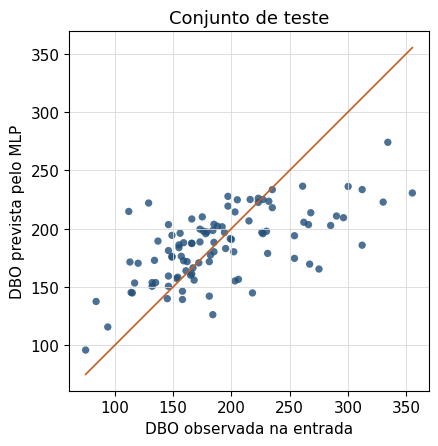

In [9]:
def salvar(fig, nome):
    fig.tight_layout()
    fig.savefig(FIGURAS / f"{nome}.pdf")
    fig.savefig(FIGURAS / f"{nome}.png", dpi=150)
    plt.show()


fig, ax = plt.subplots()
ax.scatter(y_teste, y_mlp, s=28, alpha=0.8, c=COR, edgecolors="none")
limites = [
    min(y_teste.min(), y_mlp.min()),
    max(y_teste.max(), y_mlp.max()),
]
ax.plot(limites, limites, color=COR_REF, linewidth=1.2)
ax.set_xlabel("DBO observada na entrada")
ax.set_ylabel("DBO prevista pelo MLP")
ax.set_title("Conjunto de teste")
ax.set_aspect("equal", adjustable="box")
salvar(fig, "observado_previsto")


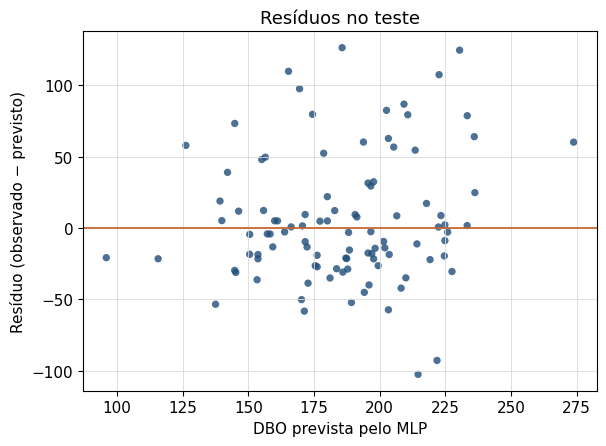

In [10]:
fig, ax = plt.subplots()
ax.scatter(y_mlp, residuo, s=28, alpha=0.8, c=COR, edgecolors="none")
ax.axhline(0, color=COR_REF, linewidth=1.2)
ax.set_xlabel("DBO prevista pelo MLP")
ax.set_ylabel("Resíduo (observado − previsto)")
ax.set_title("Resíduos no teste")
salvar(fig, "residuos")


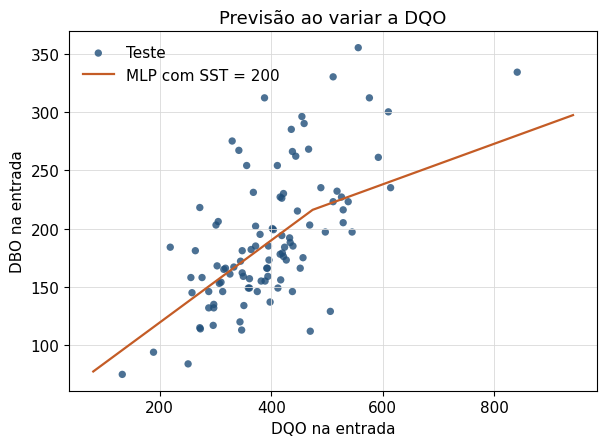

In [11]:
sst_mediana = float(X_treino["SS-E"].median())
dqo_grade = np.linspace(X_treino["DQO-E"].min(), X_treino["DQO-E"].max(), 200)
grade_dqo = pd.DataFrame({"DQO-E": dqo_grade, "SS-E": np.full(200, sst_mediana)})
dbo_grade = busca.predict(grade_dqo)

fig, ax = plt.subplots()
ax.scatter(X_teste["DQO-E"], y_teste, s=28, alpha=0.8, c=COR, edgecolors="none", label="Teste")
ax.plot(dqo_grade, dbo_grade, color=COR_REF, linewidth=1.6, label=f"MLP com SST = {sst_mediana:.0f}")
ax.set_xlabel("DQO na entrada")
ax.set_ylabel("DBO na entrada")
ax.set_title("Previsão ao variar a DQO")
ax.legend(frameon=False)
salvar(fig, "dbo_por_dqo")


## Leitura

No teste, o MLP tem MAE 33,51, RMSE 44,91 e R² 0,37. A regressão linear, com as mesmas entradas, tem MAE 32,96, RMSE 44,76 e R² 0,38. A validação cruzada repete a ordem: MAE 39,19 na rede e 38,36 na reta. A rede escolhida tem uma camada de 8 neurônios ReLU; as outras configurações da grade ficam entre 39,19 e 39,99 de MAE.

A DQO carrega a estimativa. Embaralhar DQO-E aumenta o MAE em 19,15; embaralhar SS-E aumenta em 0,10. A reta do treino é DBO = 74,04 + 0,2872·DQO − 0,0127·SST. A mediana do erro absoluto no teste é 22,07, e o percentil 90 é 79,31. A previsão fica entre 95,86 e 273,91 e comprime os extremos da DBO observada.

A análise escrita está em docs/mlp_dbo_entrada.pdf.
